(course-enzyme-comparison-superposition)=

# Path B - Module 34: Comparison & Superposition

How does your engineered mutant differ from the wild-type PETase? To quantify the structural change, you cannot just look at the coordinates. You need to **Align** both structures in space and measure the **RMSD** (Root Mean Square Deviation).

`least_rmsd_align()` returns an aligned molecular system. Use `get_rmsd()`
with the corresponding anchor selections to measure its residual RMSD. Its
selections always address atoms; the sequence provider independently maps their
amino-acid groups. Complete components containing the query anchors move.
See {ref}`Tutorial_Least_rmsd_align` and
{ref}`Cookbook_Aligning_Components_By_Sequence` for ownership and scope details.


(course-enzyme-comparison-superposition-inputs)=
## 1. Preparing a comparison

You compare PETase using the same C-alpha anchor populations
before and after fitting. The aligned system is an independent result: neither
the original query nor the reference is overwritten. Atoms outside the anchors
move when they belong to a selected component; unselected components stay fixed.

Qualify C-alpha anchors by protein membership: another peptide or an ion
can also contain an atom named CA. That extra population must not silently
enter a comparison intended for the target protein.


In [1]:
import molsysmt as msm

reference = msm.convert('pdb:6EQE', to_form='molsysmt.MolSys', structure_indices=[0])

import numpy as np
import matplotlib.pyplot as plt
puw = msm.pyunitwizard
molsys = msm.copy(reference)
# An illustrative local displacement, not a chemical mutation.
returned = msm.structure.translate(molsys,
    selection='group_index>=10 and group_index<=50', translation='[0.2, 0, 0] nm', in_place=True)
assert returned is None
atoms = msm.select(molsys, selection='atom_name=="CA" and molecule_type=="protein"')
reference_atoms = msm.select(reference, selection='atom_name=="CA" and molecule_type=="protein"')
reference_before = puw.get_value(msm.get(reference, element='atom', coordinates=True),
                                 to_unit='nm').copy()
query_before = puw.get_value(msm.get(molsys, element='atom', coordinates=True),
                             to_unit='nm').copy()


(course-enzyme-comparison-superposition-raw)=
## 2. Measuring the original difference

Measure raw RMSD over the atoms you will use as fit anchors.


In [2]:
rmsd_raw = msm.structure.get_rmsd(
    molsys, selection=atoms, reference_molecular_system=reference,
    reference_selection=reference_atoms)
print('CA RMSD before alignment:', rmsd_raw)


CA RMSD before alignment: [0.07866815903072234] nanometer


(course-enzyme-comparison-superposition-fit)=
## 3. Aligning and measuring

Keep the returned system, then measure its RMSD against the same reference.


In [3]:
aligned_molsys = msm.structure.least_rmsd_align(
    molsys, selection=atoms, reference_molecular_system=reference,
    reference_selection=reference_atoms, use_gpu=False)
rmsd_opt = msm.structure.get_rmsd(
    aligned_molsys, selection=atoms, reference_molecular_system=reference,
    reference_selection=reference_atoms)
assert np.all(puw.get_value(rmsd_opt, to_unit='nm') <=
              puw.get_value(rmsd_raw, to_unit='nm') + 1e-10)
np.testing.assert_array_equal(
    puw.get_value(msm.get(reference, element='atom', coordinates=True), to_unit='nm'),
    reference_before)
np.testing.assert_array_equal(
    puw.get_value(msm.get(molsys, element='atom', coordinates=True), to_unit='nm'),
    query_before)
print('CA RMSD after alignment:', rmsd_opt)


CA RMSD after alignment: [0.06684118446741755] nanometer


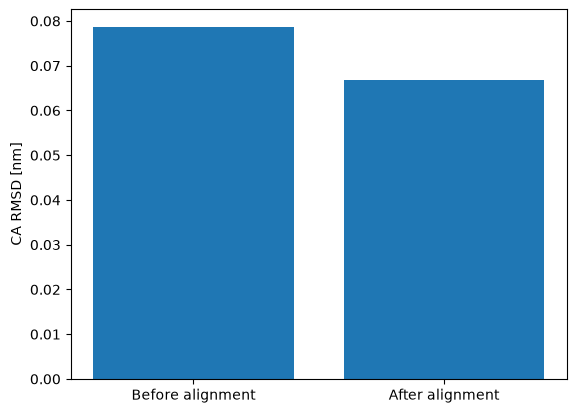

In [4]:
plt.bar(['Before alignment', 'After alignment'],
    [puw.get_value(rmsd_raw, to_unit='nm')[0], puw.get_value(rmsd_opt, to_unit='nm')[0]])
plt.ylabel('CA RMSD [nm]')
plt.show()


(course-enzyme-comparison-superposition-see-also)=
:::{seealso}
:class: dropdown

- {ref}`Tutorial_Least_rmsd_align`
- {ref}`Cookbook_Aligning_Components_By_Sequence`
- {ref}`course-core-structural-operations`
- {func}`molsysmt.structure.get_rmsd`
:::
